# SAXS asymmetry and PCI exit intensity: simulation–experiment comparison

This notebook uses the local `PCI.py` model to construct Cu-wire exit fields,

$$E_{\mathrm{out}}=E_{\mathrm{in}}\exp(-\mu t/2)\exp(-ik\delta t).$$

Two different observables are then formed. The SAXS path uses the same 20 nm voxelized wire and `PCI.py` interpolation as `clean_saxs_design`; the sample-exit PCI path retains its analytic wire chord.

1. **PCI:** the intensity immediately after the sample, $I_{\mathrm{PCI}}=|E_{\mathrm{out}}|^2$. This is `PCI.py`'s `intensity_aftertarget` and is independent of propagation length after the sample.
2. **SAXS:** the voxelized/interpolated exit field propagated to the SAXS detector with `lorentz_propagate_to_position`.

The cleaned aggregate SAXS profiles in `inputs/experimental/SAXSData/` are summarized as reference metrics, and integrated target-exit intensity is compared with `inputs/experimental/MotoPosition_Zyla_r0484.dat`.

> The legacy `DivPCI_*.tif` files are propagated images. They are not used as the exit-plane PCI observable in this notebook.

Paths are relative to this notebook; run it with `SAXS_asymmetry/` as the working directory.

In [6]:
from pathlib import Path
import numpy as np
from scipy.ndimage import shift as nd_shift
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import Markdown, display

import PCI
import saxs_asymmetry_analysis as saa

# PCI is evaluated at the sample exit. Z_DETECTOR is used only by the SAXS propagator.
# PCI.py uses nm as its base length unit. N_GRID and PIXEL_SIZE define the
# sampled source/sample field: their product is the real-space field of view.
N_GRID = 4096
PIXEL_SIZE = 8 * PCI.nm
PHOTON_ENERGY = 8.2 * PCI.keV
LAMBDA_NM = PCI.HC_KEV_NM / PHOTON_ENERGY  # X-ray wavelength lambda [nm]
Z_TARGET = 0.25 * PCI.m   # distance from the Gaussian waist plane to the wire
Z_DETECTOR = 1.31 * PCI.m  # wire-to-SAXS-detector propagation distance

# TARGET_FWHM is the full intensity width at half maximum at the wire.
# TARGET_BEAM_RADIUS is w(z): the 1/e field-amplitude radius, equivalently
# the 1/e^2 intensity radius in the Gaussian-beam convention.
TARGET_FWHM = 7.50 * PCI.um
TARGET_BEAM_RADIUS = TARGET_FWHM / np.sqrt(2 * np.log(2))

# Gaussian spreading obeys w(z)^2 = w0^2 + [lambda*z/(pi*w0)]^2.
# DIFFRACTION_TERM = lambda*z/pi has units of length squared and measures
# the diffraction broadening accumulated between the waist and the wire.
DIFFRACTION_TERM = LAMBDA_NM * Z_TARGET / np.pi
# Solve the quadratic in w0^2 using its smaller, divergent-source root.
# SOURCE_WAIST is w0 (a 1/e^2-intensity radius), not a FWHM or target size.
SOURCE_WAIST = np.sqrt(
    (TARGET_BEAM_RADIUS**2
     - np.sqrt(TARGET_BEAM_RADIUS**4 - 4 * DIFFRACTION_TERM**2)) / 2
)
WIRE_RADIUS = 5 * PCI.um       # physical radius of the cylindrical Cu wire
WIRE_VOXEL_SIZE = 20 * PCI.nm  # sampling of its projected-thickness map
WIRE_VOXEL_NUMBER = 2000       # transverse extent of the target map in voxels

q_step = 2 * np.pi / (N_GRID * PIXEL_SIZE)  # reciprocal-space bin width
x_axis_nm = (np.arange(N_GRID) - N_GRID // 2) * PIXEL_SIZE
INPUT_DIR = Path("inputs")
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "experimental_comparison" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.facecolor": "white", "axes.grid": False})

def save_figure(fig, filename):
    fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches="tight")

def show_rows(rows, columns):
    def render(value):
        if isinstance(value, (float, np.floating)):
            return f"{value:.5g}"
        return str(value)
    header = "| " + " | ".join(columns) + " |"
    divider = "| " + " | ".join(["---"] * len(columns)) + " |"
    body = [
        "| " + " | ".join(render(row[column]) for column in columns) + " |"
        for row in rows
    ]
    display(Markdown("\n".join([header, divider, *body])))

print(f"grid: {N_GRID} x {N_GRID}; sample-plane FoV: "
      f"{N_GRID * PIXEL_SIZE / PCI.um:.2f} um")
print(f"SAXS q spacing: {q_step:.4g} 1/nm")
print(f"Calculated source waist: {SOURCE_WAIST / PCI.um:.6f} um")
print(f"Target-plane beam FWHM: {TARGET_FWHM / PCI.um:g} um")

grid: 4096 x 4096; sample-plane FoV: 32.77 um
SAXS q spacing: 0.0001917 1/nm
Calculated source waist: 1.988233 um
Target-plane beam FWHM: 7.5 um


## Experimental inputs

Each cleaned SAXS payload stores `(q_positive, left, right)`. The validated loader reconstructs signed q independently for each run and removes non-finite intensity bins without resampling experiments onto a common grid.

The motor-scan arrays provide the experimental left fraction. Motor position is treated throughout as the wire position relative to the fixed beam. `inputs/experimental/MotoPosition_Zyla_r0484.dat` contains wire-motor position and XGM-normalized transmission.

In [7]:
RUN_FILES = {
    run: INPUT_DIR / "experimental" / "SAXSData" / f"profiles_cleaned_p3129_{run}.pickle"
    for run in ("r0528", "r0534", "r0546")
}
profiles = saa.load_profiles(RUN_FILES)
profile_analysis = saa.analyze_profiles(profiles)

experimental_rows = []
for run, profile in profiles.items():
    left = float(np.sum(profile.intensity[profile.q < 0]))
    right = float(np.sum(profile.intensity[profile.q > 0]))
    metrics = profile_analysis[run]
    experimental_rows.append({
        "run": run,
        "left fraction": left / (left + right),
        "weighted RMS": metrics["weighted_rms"],
        "unweighted RMS": metrics["legacy_unweighted_rms"],
        "fitted center (1/nm)": metrics["center"],
    })

transmission_data = np.loadtxt(INPUT_DIR / "experimental" / "MotoPosition_Zyla_r0484.dat")
if transmission_data.shape[0] != 3 and transmission_data.shape[1] == 3:
    transmission_data = transmission_data.T
if transmission_data.shape[0] != 3:
    raise ValueError("MotoPosition_Zyla_r0484.dat must contain three rows.")
transmission_position_raw = transmission_data[0].astype(float)
transmission_xgm = transmission_data[2].astype(float)

show_rows(
    experimental_rows,
    ["run", "left fraction", "weighted RMS", "unweighted RMS",
     "fitted center (1/nm)"],
)

| run | left fraction | weighted RMS | unweighted RMS | fitted center (1/nm) |
| --- | --- | --- | --- | --- |
| r0528 | 0.69674 | 0.1932 | 0.42769 | 0.0012154 |
| r0534 | 0.49285 | 0.25132 | 0.4169 | 0.016059 |
| r0546 | 0.64225 | 0.11734 | 0.19229 | -0.0024389 |

## PCI exit field and SAXS forward model

A Gaussian source is evaluated at its waist and at the target plane. The first figure checks the computed central intensity profiles against the expected source radius and target FWHM before any sample transmission is applied. For SAXS, the vertical 10 µm Cu wire uses the same 20 nm voxel projection as `clean_saxs_design`: its projected chord is shifted on the target grid and `PCI.py.propagate_through_target` interpolates that projection onto the 8 nm XFEL grid before applying absorption and phase. The existing analytic-chord construction is retained for the sample-exit PCI and transmission comparisons. Only `make_saxs_intensity` uses `Z_DETECTOR`.

Rayleigh [m]:  0.08213569966858816
Radius [um]:  inf 0.15120024068359483
the beam waist on the target plane is  1.988 um
the FWHM beam waist on the target plane is  2.341 um
the target postion is 0.000 m
complex q parameter is 82135699.66858816j
Rayleigh [m]:  0.08213569966858816
Radius [um]:  276985.09264019405 0.15120024068359483
the beam waist on the target plane is  6.370 um
the FWHM beam waist on the target plane is  7.500 um
the target postion is 0.250 m
complex q parameter is (249999999.99999997+82135699.66858815j)


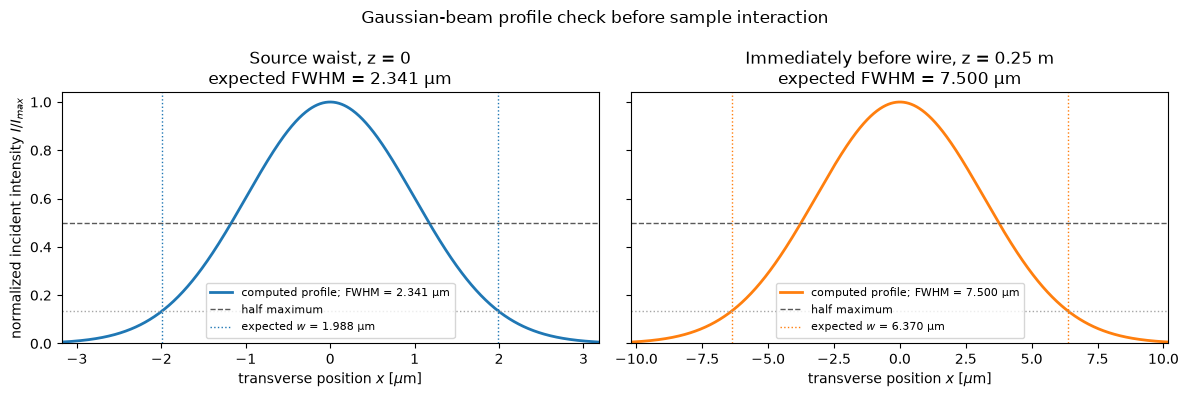

Source FWHM: expected 2.340966 um, measured 2.340970 um
Pre-target FWHM: expected 7.500000 um, measured 7.500001 um


In [8]:
# The source is defined at its waist plane by w0=SOURCE_WAIST. PCI.py then
# evaluates the expanded Gaussian envelope, curved phase front, and Gouy
# phase at the wire plane Z_TARGET downstream.
xfel = PCI.gaussian_XFEL(
    waist=SOURCE_WAIST,
    pixel_number=N_GRID,
    pixel_size=PIXEL_SIZE,
    photon_energy=PHOTON_ENERGY,
)
# Extract only the central source-plane profile, then release the full field
# before constructing the 4096^2 target-plane field used later.
beam_center = N_GRID // 2
field_at_source = xfel.initialize_to_position(0.0, reset=False)
source_profile = np.abs(field_at_source[beam_center, :])**2
source_profile /= source_profile.max()
del field_at_source

# This is the incident field immediately before the wire; no absorption or
# sample-induced phase has been applied yet.
field_at_target = xfel.initialize_to_position(Z_TARGET, reset=False)
target_profile = np.abs(field_at_target[beam_center, :])**2
target_profile /= target_profile.max()
beam_axis_um = x_axis_nm / PCI.um

def measured_fwhm(axis, normalized_profile):
    """Return the FWHM using linear interpolation at both half-max crossings."""
    peak = int(np.argmax(normalized_profile))
    left = np.interp(0.5, normalized_profile[:peak + 1], axis[:peak + 1])
    right = np.interp(
        0.5, normalized_profile[peak:][::-1], axis[peak:][::-1]
    )
    return right - left

source_radius_um = SOURCE_WAIST / PCI.um
target_radius_um = TARGET_BEAM_RADIUS / PCI.um
source_expected_fwhm_um = source_radius_um * np.sqrt(2 * np.log(2))
source_measured_fwhm_um = measured_fwhm(beam_axis_um, source_profile)
target_measured_fwhm_um = measured_fwhm(beam_axis_um, target_profile)

beam_figure, beam_axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
beam_cases = (
    (beam_axes[0], source_profile, source_radius_um, source_expected_fwhm_um,
     source_measured_fwhm_um, "Source waist, z = 0", "tab:blue"),
    (beam_axes[1], target_profile, target_radius_um, TARGET_FWHM / PCI.um,
     target_measured_fwhm_um, "Immediately before wire, z = 0.25 m", "tab:orange"),
)
for axis, profile, radius_um, expected_fwhm_um, measured_width_um, title, color in beam_cases:
    axis.plot(beam_axis_um, profile, color=color, lw=2,
              label=f"computed profile; FWHM = {measured_width_um:.3f} µm")
    axis.axhline(0.5, color="0.35", ls="--", lw=1, label="half maximum")
    axis.axhline(np.exp(-2), color="0.65", ls=":", lw=1)
    axis.axvline(-radius_um, color=color, ls=":", lw=1)
    axis.axvline(radius_um, color=color, ls=":", lw=1,
                 label=fr"expected $w$ = {radius_um:.3f} µm")
    axis.set_xlim(-1.6 * radius_um, 1.6 * radius_um)
    axis.set_ylim(0, 1.04)
    axis.set_xlabel(r"transverse position $x$ [$\mu$m]")
    axis.set_title(title + f"\nexpected FWHM = {expected_fwhm_um:.3f} µm")
    axis.legend(fontsize=8)
beam_axes[0].set_ylabel(r"normalized incident intensity $I/I_{max}$")
beam_figure.suptitle("Gaussian-beam profile check before sample interaction")
beam_figure.tight_layout()
save_figure(beam_figure, "00_gaussian_beam_source_and_target_profiles.png")
plt.show()

print(f"Source FWHM: expected {source_expected_fwhm_um:.6f} um, "
      f"measured {source_measured_fwhm_um:.6f} um")
print(f"Pre-target FWHM: expected {TARGET_FWHM / PCI.um:.6f} um, "
      f"measured {target_measured_fwhm_um:.6f} um")

copper = PCI.Cu()
# These are the coefficients used in PCI.py's thin-object transmission.
# The factor 1/2 converts Beer-Lambert intensity attenuation exp(-mu*t)
# to field-amplitude attenuation exp(-mu*t/2); k*delta*t is phase delay.
absorption_coefficient_nm = (
    copper.get_n_refraction_beta(PHOTON_ENERGY) * PHOTON_ENERGY * 10
)
phase_coefficient_nm = copper._get_phase_shift(PHOTON_ENERGY)

class projected_wire(PCI.wire):
    """Memory-efficient projected path length through a cylindrical wire."""
    def _get_projection(self, volume=None):
        transverse_px = np.arange(self.voxel_number) - self.voxel_number // 2
        radius_px = self.radius1_nm / self.voxel_size
        inside = np.clip(radius_px**2 - transverse_px**2, 0, None)
        profile = np.where(
            np.abs(transverse_px) <= radius_px,
            (2 * np.floor(np.sqrt(inside)) + 1) * self.voxel_size,
            0.0,
        )[None, :]
        projection = np.broadcast_to(
            profile, (self.voxel_number, self.voxel_number)
        ).copy()
        self._density1 = nd_shift(
            projection, np.asarray(self.position_xy) / self.voxel_size,
            order=1, mode="constant", cval=0, prefilter=False,
        )
        return self._density1

def make_wire_target(wire_offset_um):
    """Build the same translated 20 nm voxelized wire used by Clean SAXS."""
    return projected_wire(
        "wire", photon_Energy=PHOTON_ENERGY, radius=WIRE_RADIUS,
        material=PCI.Cu, position=[0, wire_offset_um * PCI.um, Z_TARGET],
        voxel_size=WIRE_VOXEL_SIZE, voxel_number=WIRE_VOXEL_NUMBER,
    )

def make_saxs_exit_field(wire_offset_um):
    """Apply absorption and phase to form the complex field just after the wire."""
    return xfel.propagate_through_target(
        make_wire_target(wire_offset_um), reset=False,
        field_in=field_at_target, photon_energy=PHOTON_ENERGY,
    )

def wire_chord_nm(wire_offset_um):
    """Analytic chord retained only for the separate transmission curve."""
    transverse_nm = x_axis_nm - wire_offset_um * PCI.um
    return 2 * np.sqrt(
        np.clip(WIRE_RADIUS**2 - transverse_nm**2, 0.0, None)
    )

def make_pci_exit_field(wire_offset_um):
    """Form the analytic-chord exit field; no sample-to-detector propagation."""
    thickness = np.broadcast_to(
        wire_chord_nm(wire_offset_um), (N_GRID, N_GRID)
    )
    sample_factor = np.exp(
        (-0.5 * absorption_coefficient_nm - 1j * phase_coefficient_nm)
        * thickness
    )
    return field_at_target * sample_factor

def make_saxs_intensity(exit_field):
    """Fresnel-propagate E_exit and return detector intensity |E|^2."""
    # The single-FFT SAXS propagator maps the sample grid to a rescaled
    # detector grid with spacing DeltaX = lambda*z/(N*DeltaX_sample).
    saxs_field = xfel.lorentz_propagate_to_position(
        position=Z_DETECTOR,
        field_in=exit_field,
        photon_energy=PHOTON_ENERGY,
        reset=False,
    )
    return np.abs(saxs_field)**2



## PCI exit image and SAXS detector image

Each row of output uses one wire offset from -10 to +10 um in 2.5 um steps. The left panel is the PCI quantity requested here: sample-exit intensity. It has no detector coordinate and no propagation-length parameter. The right panel is the SAXS intensity after propagation by `Z_DETECTOR`.

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


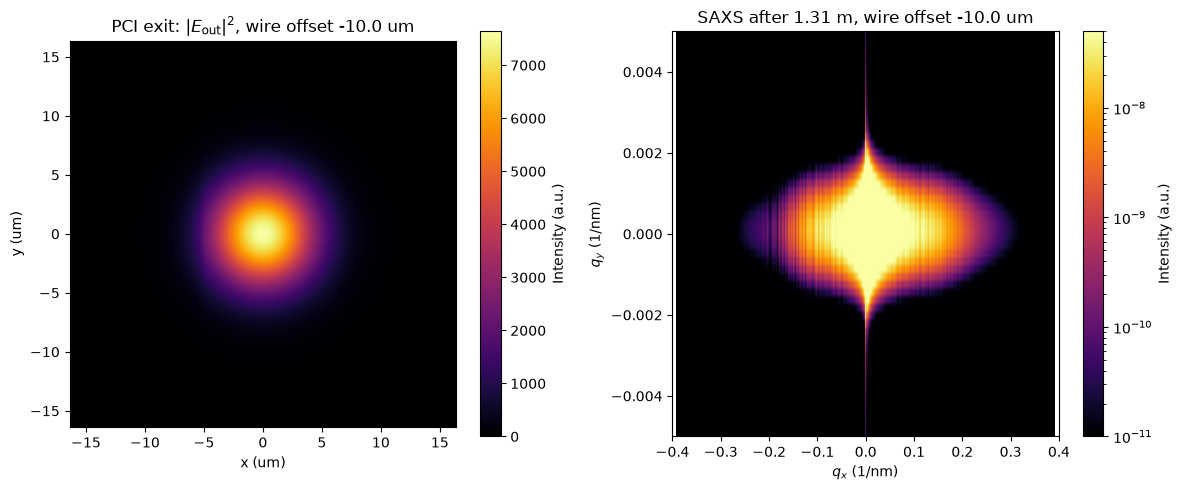

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


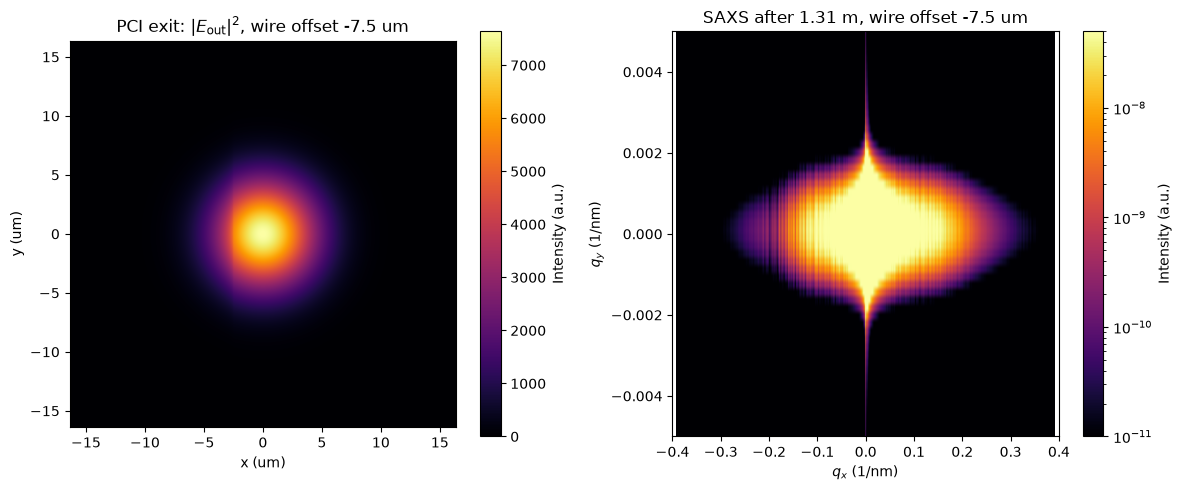

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


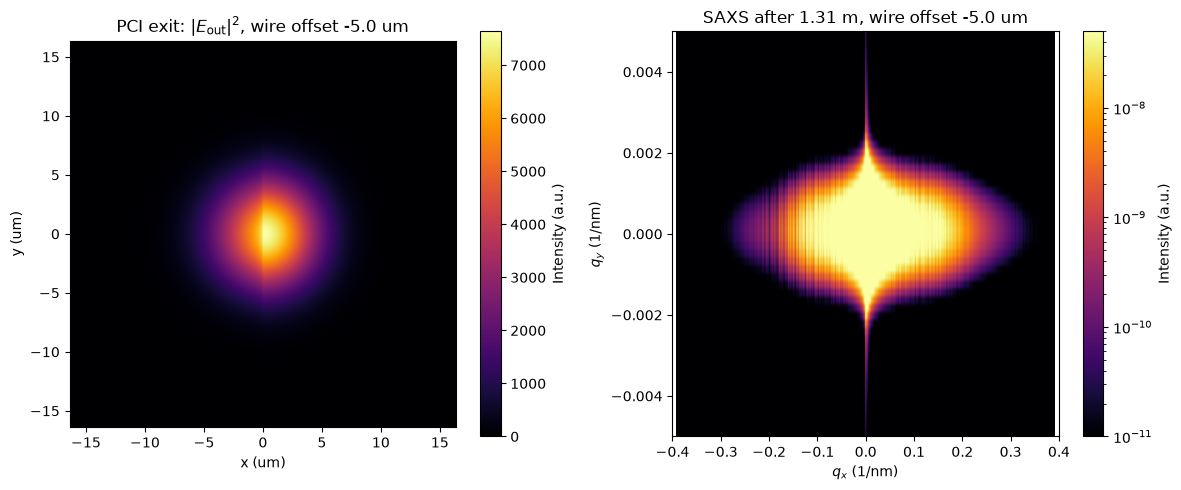

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


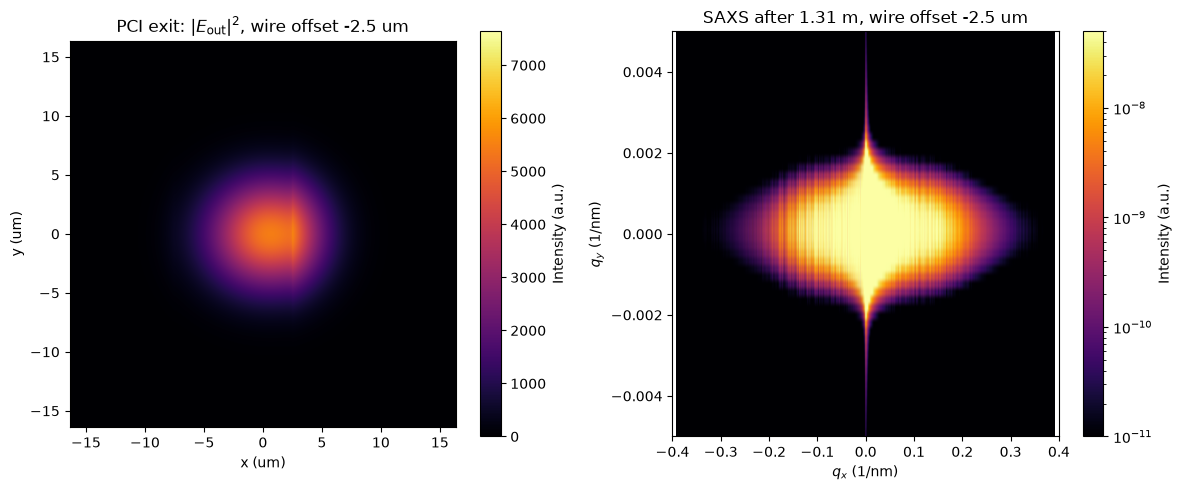

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


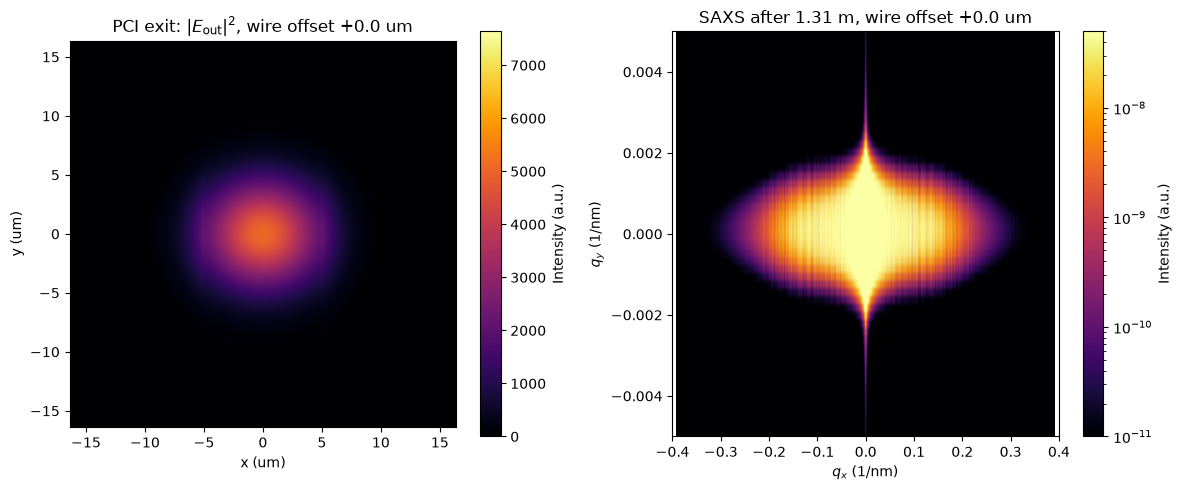

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


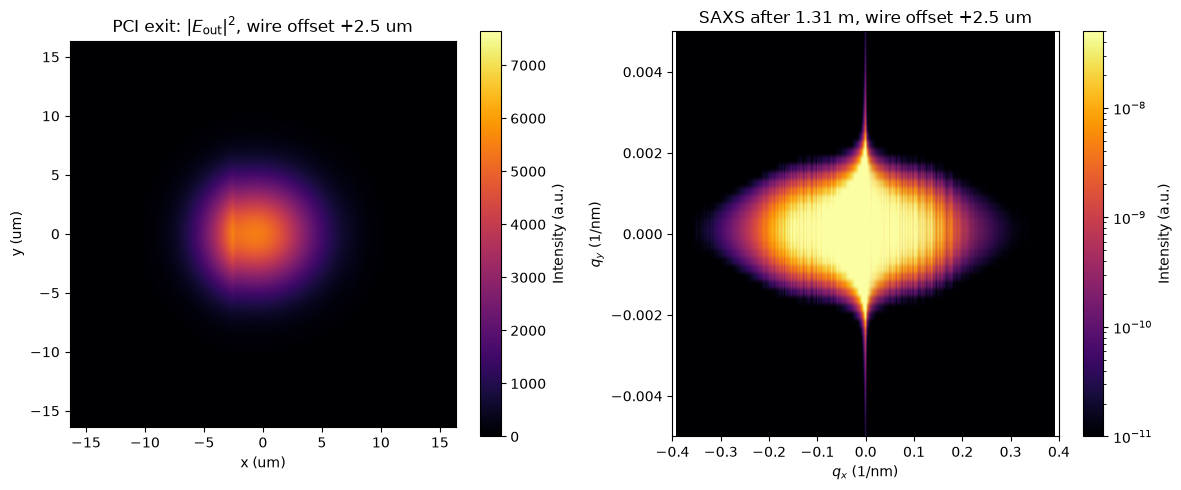

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


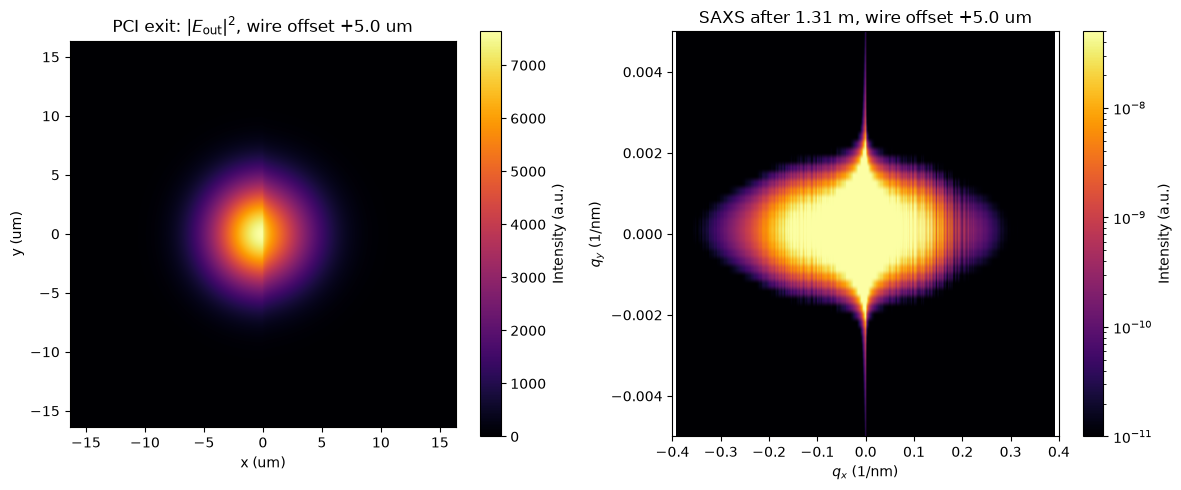

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


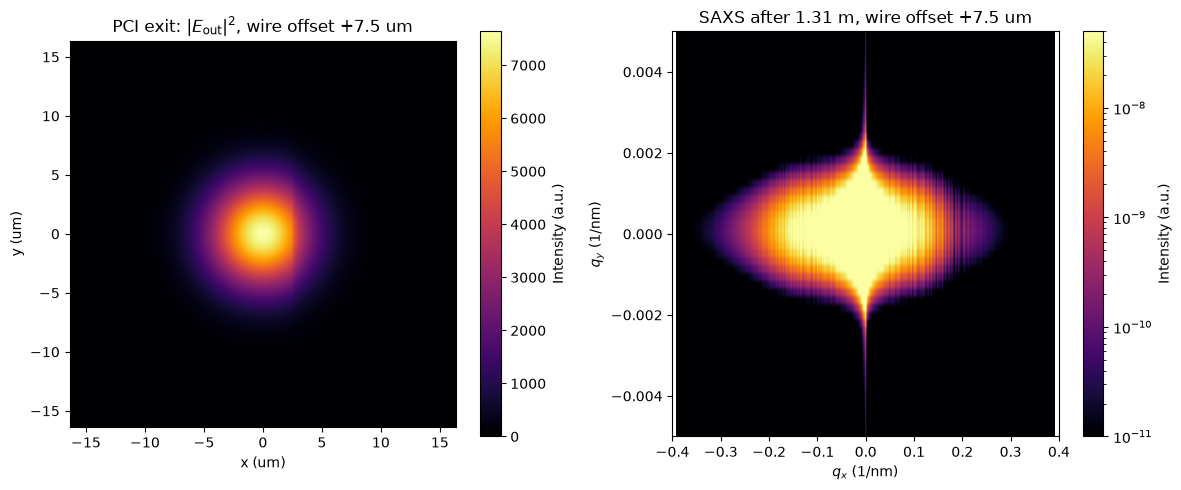

mu is 4.0906392887346616e-05 [1/um]
The position is 1310000000.000


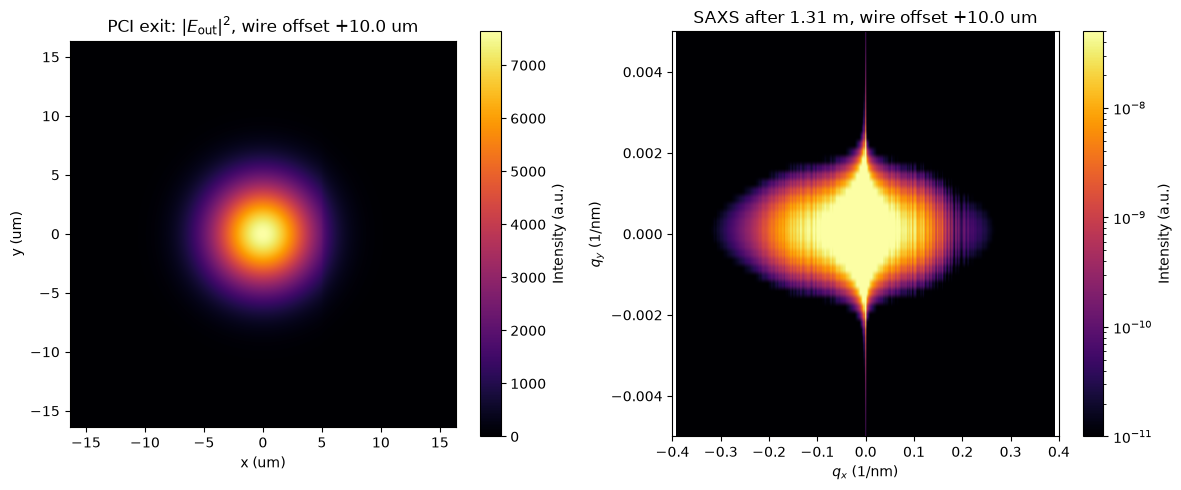

In [9]:
sample_extent_um = [
    x_axis_nm[0] / PCI.um, x_axis_nm[-1] / PCI.um,
    x_axis_nm[0] / PCI.um, x_axis_nm[-1] / PCI.um,
]
q_extent = [-q_step * N_GRID / 2, q_step * N_GRID / 2] * 2

image_wire_offsets_um = np.arange(-10.0, 10.0 + 2.5 / 2, 2.5)
pci_vmax = float(np.max(np.abs(field_at_target)**2))

for wire_offset_um in image_wire_offsets_um:
    pci_exit_field = make_pci_exit_field(wire_offset_um)
    saxs_exit_field = make_saxs_exit_field(wire_offset_um)
    pci_image = np.abs(pci_exit_field)**2
    saxs_image = make_saxs_intensity(saxs_exit_field)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    im0 = axes[0].imshow(
        pci_image, origin="lower", extent=sample_extent_um, cmap="inferno",
        vmin=0, vmax=pci_vmax, aspect="equal",
    )
    axes[0].set(
        xlabel="x (um)", ylabel="y (um)",
        title=rf"PCI exit: $|E_{{\rm out}}|^2$, wire offset {wire_offset_um:+.1f} um",
    )
    fig.colorbar(im0, ax=axes[0], label="Intensity (a.u.)")

    im1 = axes[1].imshow(
        saxs_image, origin="lower", extent=q_extent, cmap="inferno",
        norm=LogNorm(vmin=1e-11, vmax=5e-8), aspect="auto",
    )
    axes[1].set(
        xlabel=r"$q_x$ (1/nm)", ylabel=r"$q_y$ (1/nm)",
        title=(f"SAXS after {Z_DETECTOR / PCI.m:.2f} m, "
               f"wire offset {wire_offset_um:+.1f} um"),
        xlim=(-0.4, 0.4), ylim=(-0.005, 0.005),
    )
    fig.colorbar(im1, ax=axes[1], label="Intensity (a.u.)")
    fig.tight_layout()
    offset_tag = f"{wire_offset_um:+.1f}".replace("+", "p").replace("-", "m").replace(".", "p")
    save_figure(fig, f"01_exit_pci_and_saxs_offset_{offset_tag}um.png")
    plt.show()
    plt.close(fig)
    del pci_exit_field, saxs_exit_field, pci_image, saxs_image

## Target-exit intensity / transmission comparison

The simulated curve is

$$T_{\mathrm{exit}}(x_0)=
\frac{\sum_{x,y}|E_{\mathrm{out}}(x,y;x_0)|^2}
     {\sum_{x,y}|E_{\mathrm{in}}(x,y)|^2}.$$

It is calculated before any propagation and therefore contains no sample-to-detector distance. Simulation and experiment are normalized by their own maxima because no absolute intensity calibration is applied.

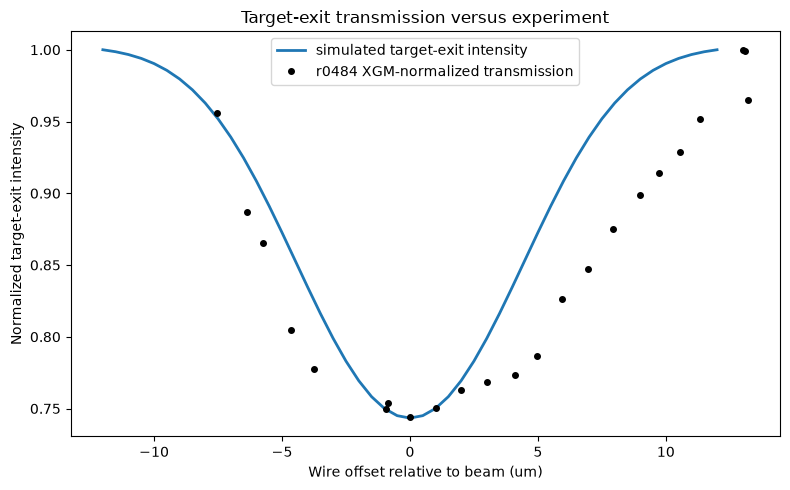

In [10]:
transmission_wire_offsets_um = np.linspace(-12.0, 12.0, 49)
incident_sample_plane_intensity = np.abs(field_at_target)**2
incident_column_power = np.sum(incident_sample_plane_intensity, axis=0)
incident_sum = float(np.sum(incident_column_power))

sim_exit_transmission = []
for wire_offset_um in transmission_wire_offsets_um:
    # The wire attenuation is y-independent, so summing incident intensity
    # along y first is exactly equivalent to integrating the full 2-D exit image.
    exit_column_power = incident_column_power * np.exp(
        -absorption_coefficient_nm * wire_chord_nm(wire_offset_um)
    )
    sim_exit_transmission.append(float(np.sum(exit_column_power)) / incident_sum)
sim_exit_transmission = np.asarray(sim_exit_transmission)
sim_exit_transmission /= sim_exit_transmission.max()

# The first row is a motor coordinate near 22.86. Convert differences from mm
# to um and place the measured transmission minimum at zero offset.
exp_minimum = int(np.nanargmin(transmission_xgm))
exp_transmission_position_um = (
    transmission_position_raw - transmission_position_raw[exp_minimum]
) * 1e3
exp_transmission = transmission_xgm / np.nanmax(transmission_xgm)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    transmission_wire_offsets_um, sim_exit_transmission, "-", lw=2,
    label="simulated target-exit intensity",
)
ax.plot(
    exp_transmission_position_um, exp_transmission, "ko", ms=4,
    label="r0484 XGM-normalized transmission",
)
ax.set(
    xlabel="Wire offset relative to beam (um)",
    ylabel="Normalized target-exit intensity",
    title="Target-exit transmission versus experiment",
)
ax.legend()
fig.tight_layout()
save_figure(fig, "04_exit_transmission.png")
plt.show()